# Parametric VaR: Sensitivity & Stress Testing
**Validator:** Cassie Wan

**Project Specifications:** 1-day 99% VaR, $1M SPY portfolio

Baseline: 250-day rolling window

Alternatives: 125-day and 500-day windows

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2

RAW = '../../data/spy_daily_raw.csv'
COMB = '../../results/combined_var_results.csv'
V = 1_000_000
P = 0.01
Z = norm.ppf(0.99)

## Clean and prepare the raw data for analysis
df = pd.read_csv(RAW, encoding='utf-8-sig')
df.columns = [c.strip() for c in df.columns]
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values("Date").reset_index(drop=True)
required_cols = ["Last Price"]
df = df.dropna(subset=required_cols).reset_index(drop=True)
df = df.loc[df.groupby("Date")["Last Price"].idxmax()].sort_values("Date").reset_index(drop=True)
df = df[df["Date"] >= pd.Timestamp('2010-01-01')].reset_index(drop=True)

## Calculate returns and P&L
df["SPY_Return"] = df['Last Price'].pct_change()
df["Portfolio P&L"] = V * df.SPY_Return

In [2]:
## Calculate VaR based off of window length and zero-mean assumption
def var(window, zero_mean=False):
    mu = df.SPY_Return.rolling(window).mean().shift(1)
    sd = df.SPY_Return.rolling(window).std().shift(1)
    return V * (Z * sd - (0 if zero_mean else mu))

## Evaluate VaR across different rolling windows
tests = {'125-day': var(125), 'Baseline (250-day)': var(250), '500-day': var(500), 
         'Zero-mean (125-day)': var(125, zero_mean=True), 'Zero-mean (250-day)': var(250, zero_mean=True), 'Zero-mean (500-day)': var(500, zero_mean=True)}
for k, v in tests.items(): df[k] = v
start = max(df.Date[df[k].first_valid_index()] for k in tests)
sensitivity = df[df.Date >= start].reset_index(drop=True)
print('Common evaluation period:', sensitivity.Date.iloc[0].date(), 'to', sensitivity.Date.iloc[-1].date())
print('Forecasts:', len(sensitivity))

Common evaluation period: 2011-12-28 to 2026-08-31
Forecasts: 3689


### Parameter Sensitivity

In [3]:
## Kupiec Test
def kupiec(n, x, p = P):
    p_hat = x / n
    ll0 = (n - x) * np.log(1-p) + x * np.log(p)
    ll1 = (n - x) * np.log(1-p_hat) + (x * np.log(p_hat) if x > 0 else 0)
    lr = -2 * (ll0-ll1)
    return lr, chi2.sf(lr, 1)

## Christoffersen Test
def christoffersen(e):
    a, b = e[:-1], e[1:]
    n00 = int(((a==0) & (b==0)).sum()); n01 = int(((a==0)&(b==1)).sum())
    n10 = int(((a==1)&(b==0)).sum()); n11 = int(((a==1)&(b==1)).sum())
    pi01 = n01 / (n00 + n01)
    pi11 = n11 / (n10 + n11)
    pi = (n01 + n11) / (n00 + n01 + n10 + n11)
    ll = lambda k, m, q: (k * np.log(q) if k > 0 else 0) + (m * np.log(1 - q) if m > 0 else 0)
    lr = -2 * (ll (n01 + n11, n00 + n10, pi) - (ll (n01, n00, pi01) + ll(n11, n10, pi11)))
    return (n00, n01, n10, n11), pi01, pi11, lr, chi2.sf(lr, 1)

In [4]:
## Apply to all alternative parameters
rows = {}
for k in tests:
    ex = (sensitivity["Portfolio P&L"] < -sensitivity[k]).astype(int)
    sensitivity['E_'+k] = ex
    n, x = len(sensitivity), int(ex.sum())

    lr_uc, p_uc = kupiec(n, x)
    counts, pi01, pi11, lr_ind, p_ind = christoffersen(ex.values)
    lr_cc = lr_uc + lr_ind; p_cc = chi2.sf(lr_cc, 2)

    rows[k] = {'Average VaR ($)': sensitivity[k].mean(), 'Maximum VaR ($)': sensitivity[k].max(), 'Exceptions': x, 'Expected': n*P,
               'Exception rate': x/n, 'Kupiec p': p_uc, 'Christoffersen p': p_ind, 'P(exc | exc yesterday)': pi11,
               'VaR coeff. of variation': sensitivity[k].std()/sensitivity[k].mean(), 'Largest loss / VaR': (-sensitivity["Portfolio P&L"]/sensitivity[k])[ex==1].max()}
sens = pd.DataFrame(rows).T
display(sens)

,Average VaR ($),Maximum VaR ($),Exceptions,Expected,Exception rate,Kupiec p,Christoffersen p,P(exc | exc yesterday),VaR coeff. of variation,Largest loss / VaR
125-day,22116.084871,65638.173469,96.0,36.89,0.026023,3.733336e-16,1.842208e-04,0.104167,0.473024,4.020560
Baseline (250-day),23019.549118,48837.895037,96.0,36.89,0.026023,3.733336e-16,3.332197e-05,0.114583,0.387066,4.167596
500-day,23775.263450,37995.236337,90.0,36.89,0.024397,1.149853e-13,1.281602e-06,0.133333,0.276997,3.789738
Zero-mean (125-day),22654.606418,65808.578822,92.0,36.89,0.024939,1.777765e-14,8.666180e-05,0.108696,0.452628,3.709945
Zero-mean (250-day),23541.184677,49619.918405,93.0,36.89,0.025210,6.876869e-15,1.770674e-05,0.118280,0.373290,3.877437
Zero-mean (500-day),24288.173814,38446.337516,82.0,36.89,0.022228,1.279760e-10,1.492220e-07,0.146341,0.271399,3.780672


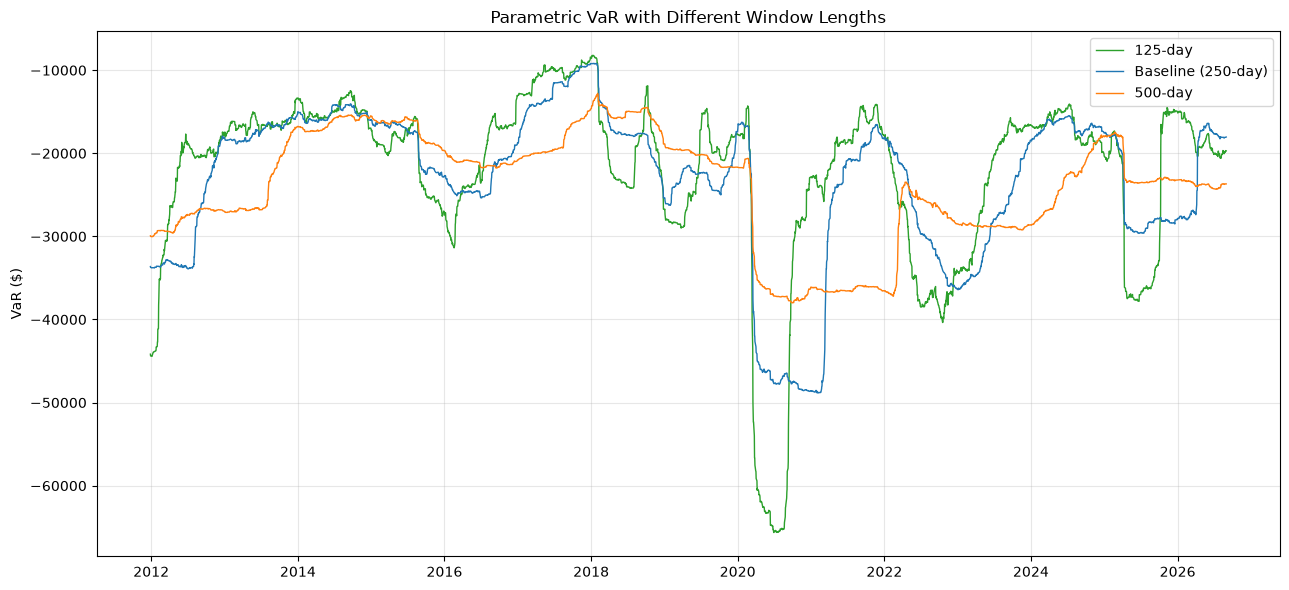

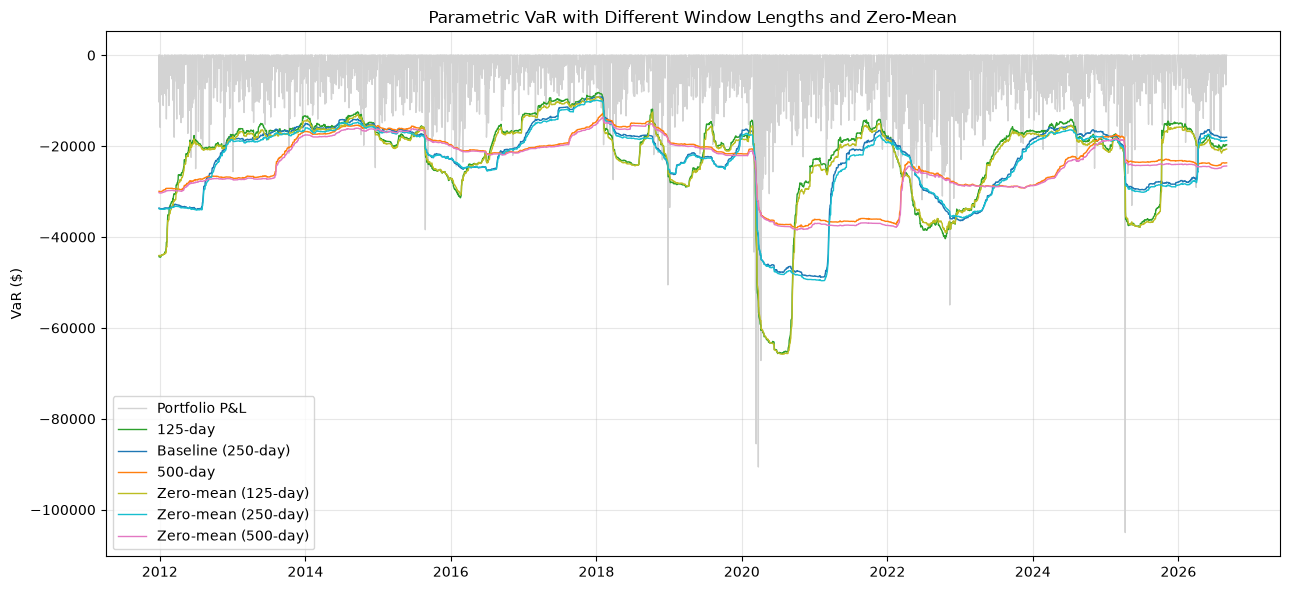

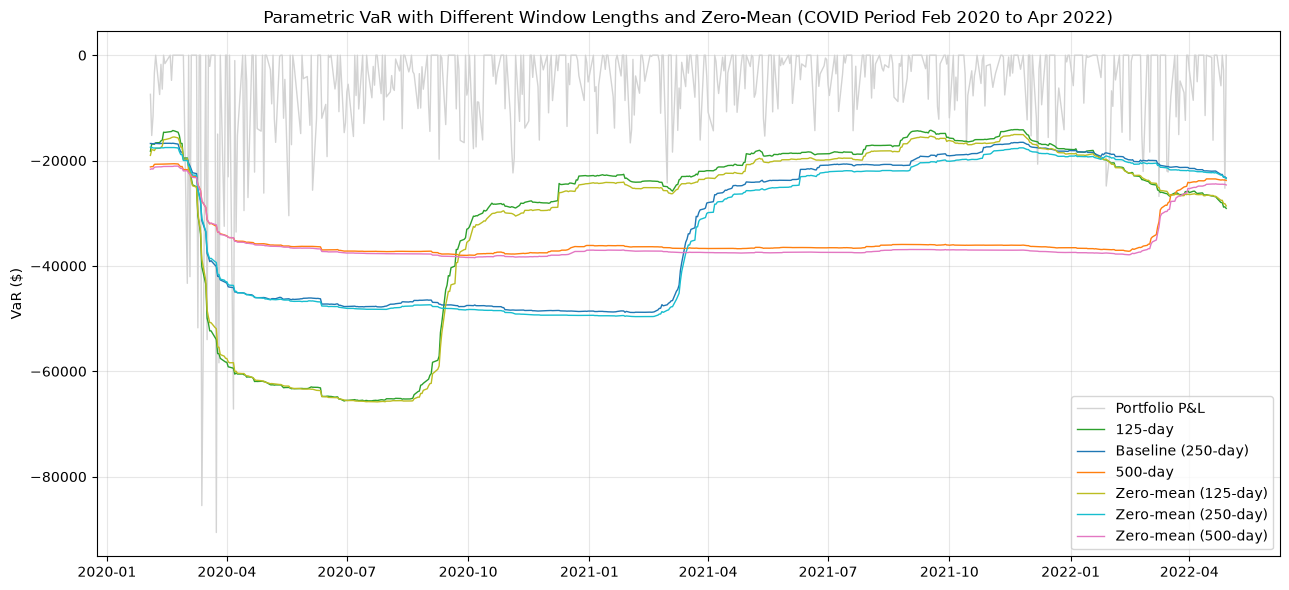

In [5]:
## Parametric VaR with different window lengths
fig, ax = plt.subplots(figsize=(13,6))
for k, col in zip(['125-day', 'Baseline (250-day)', '500-day'], ['tab:green', 'tab:blue', 'tab:orange']):
    ax.plot(sensitivity.Date, -sensitivity[k], label=k, color=col, lw=1)
ax.set_title('Parametric VaR with Different Window Lengths')
ax.set_ylabel('VaR ($)')
ax.grid(alpha=.3)
ax.legend()
plt.tight_layout()
plt.savefig('../../results/validation/parametric/figures/parametric_window_sensitivity_full.png', dpi=200)
plt.show()

## Parametric VaR with different window lengths and zero-mean
fig, ax = plt.subplots(figsize=(13,6))
for k, col in zip(['Portfolio P&L', '125-day', 'Baseline (250-day)', '500-day','Zero-mean (125-day)', 'Zero-mean (250-day)', 'Zero-mean (500-day)'],
                  ['lightgray', 'tab:green', 'tab:blue', 'tab:orange', 'tab:olive', 'tab:cyan', 'tab:pink']):
    ax.plot(sensitivity.Date, -sensitivity[k].clip(lower=0), label=k, color=col, lw=1)
ax.set_title('Parametric VaR with Different Window Lengths and Zero-Mean')
ax.set_ylabel('VaR ($)')
ax.grid(alpha=.3)
ax.legend()
plt.tight_layout()
plt.savefig('../../results/validation/parametric/figures/parametric_window_zero_mean_sensitivity_full.png', dpi=200)
plt.show()

## Parametric VaR with different window lengths during COVID period
focus = sensitivity[(sensitivity.Date>='2020-02-01')&(sensitivity.Date<='2022-04-30')]
fig, ax = plt.subplots(figsize=(13,6))
for k, col in zip(['Portfolio P&L', '125-day', 'Baseline (250-day)', '500-day','Zero-mean (125-day)', 'Zero-mean (250-day)', 'Zero-mean (500-day)'],
                  ['lightgray', 'tab:green', 'tab:blue', 'tab:orange', 'tab:olive', 'tab:cyan', 'tab:pink']):
    ax.plot(focus.Date, -focus[k].clip(lower=0), label=k, color=col, lw=1)
ax.set_title('Parametric VaR with Different Window Lengths and Zero-Mean (COVID Period Feb 2020 to Apr 2022)')
ax.set_ylabel('VaR ($)')
ax.grid(alpha=.3)
ax.legend()
plt.tight_layout()
plt.savefig('../../results/validation/parametric/figures/parametric_window_zero_mean_sensitivity_covid.png', dpi=200)
plt.show()

### COVID Stress Period Analysis (Feb-Apr 2020)

In [6]:
## Load combined model output data
c = pd.read_csv(COMB, parse_dates=['Date'])
stress = c[(c.Date>='2020-02-01')&(c.Date<='2020-04-30')].copy()
print('Trading days in stress window:', len(stress))

## Compare VaR models in the stress window
rows = []
for col in ['Historical_VaR','Parametric_VaR','EWMA_VaR']:
    ex = stress["Portfolio P&L"] < -stress[col]; m = (-stress["Portfolio P&L"]/stress[col])[ex]
    rows.append({'Model': col.replace('_VaR',''), 'Exceptions': int(ex.sum()), 'Largest loss / VaR': m.max(), 'Peak VaR in window ($)': stress[col].max()})
display(pd.DataFrame(rows).set_index('Model'))
print('Parametric exception dates:', [d.strftime('%m-%d') for d in stress.Date[stress["Portfolio P&L"] < -stress.Parametric_VaR]])

## Compare parametric VaR with different parameters in the stress window
covid = sensitivity[(sensitivity.Date>='2020-02-01')&(sensitivity.Date<='2020-04-30')]
for k in ['125-day', 'Baseline (250-day)', '500-day', 'Zero-mean (125-day)', 'Zero-mean (250-day)', 'Zero-mean (500-day)']:
    ex = covid["Portfolio P&L"] < -covid[k]; print(f"{k:20s} stress-window exceptions: {int(ex.sum())}, largest loss/VaR {(-covid["Portfolio P&L"]/covid[k])[ex].max():.2f}")

Trading days in stress window: 62


KeyError: 'Portfolio P&L'

In [ ]:
## Benchmark parametric VaR vs P&L during COVID period
fig, ax = plt.subplots(figsize=(13,6))
ax.bar(stress.Date, stress["Portfolio P&L"], color='black', alpha=.25, width=0.8, label='Daily Portfolio P&L')
ax.plot(stress.Date, -stress.Parametric_VaR, color='tab:blue', lw=1.8, label='Parametric VaR')
ex = stress[stress["Portfolio P&L"] < -stress.Parametric_VaR]
ax.scatter(ex.Date, ex["Portfolio P&L"], color='red', zorder=4, s=28, label=f'Parametric exceptions ({len(ex)})')
ax.set_title('Parametric VaR vs Portfolio P&L during COVID period')
ax.set_ylabel('P&L / VaR ($)')
ax.grid(alpha=.3)
ax.legend()
plt.tight_layout()
plt.savefig('../../results/validation/parametric/figures/parametric_covid_pnl_vs_var.png', dpi=200)
plt.show()
